In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

crop_df = pd.read_csv('crop_yield.csv')

In [2]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [3]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [4]:
crop_df.dtypes

FARM_ID             object
CROP_TYPE           object
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE        object
DISTRICT            object
SEASON              object
FERTILIZER_USED     object
YIELD_VALUE          int64
dtype: object

In [5]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [6]:
crop_df.describe (include = "object")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [7]:
crop_df = crop_df.dropna(subset=['YIELD_KG']).copy()
crop_df

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,NaN,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.0,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.0,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,NaN,18/03/2031,Lahore,Rabi,NaN,40000


In [8]:
crop_df['AREA_ACRES']= crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())
crop_df

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,18/03/2031,Lahore,Rabi,NaN,40000


In [9]:
crop_df['AREA_ACRES'].isnull().sum()

0

In [10]:
crop_df['DISTRICT']=crop_df['DISTRICT'].fillna('Unknown')
crop_df

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,15/03/2031,Unknown,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,18/03/2031,Lahore,Rabi,NaN,40000


In [11]:
crop_df['FERTILIZER_USED']=crop_df['FERTILIZER_USED'].fillna('No')
crop_df

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,15/03/2031,Unknown,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,18/03/2031,Lahore,Rabi,No,40000


In [12]:
crop_df['YIELD_VALUE']=crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())
crop_df


,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,15/03/2031,Unknown,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,18/03/2031,Lahore,Rabi,No,40000


In [13]:
crop_df['HARVEST_DATE'] = pd.to_datetime(
    crop_df['HARVEST_DATE'],
    errors='coerce',
    format='%d/%m/%Y'
)
crop_df

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,2023-01-01,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,2023-01-02,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,2023-01-03,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,2023-01-04,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,2023-01-05,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,2031-03-15,Unknown,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,2031-03-16,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,2031-03-17,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,2031-03-18,Lahore,Rabi,No,40000


In [14]:
crop_df['HARVEST_DATE'].dtype

dtype('<M8[ns]')

In [15]:
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace('F', '').astype(int)

In [16]:
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [17]:
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                  object
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[ns]
DISTRICT                   object
SEASON                     object
FERTILIZER_USED            object
YIELD_VALUE                 int64
dtype: object

In [18]:
crop_yield =crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
crop_yield

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


In [19]:
crop_pivot = crop_df.pivot_table(
    values='YIELD_KG',
    index='HARVEST_DATE',
    aggfunc='sum'
)

crop_pivot

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


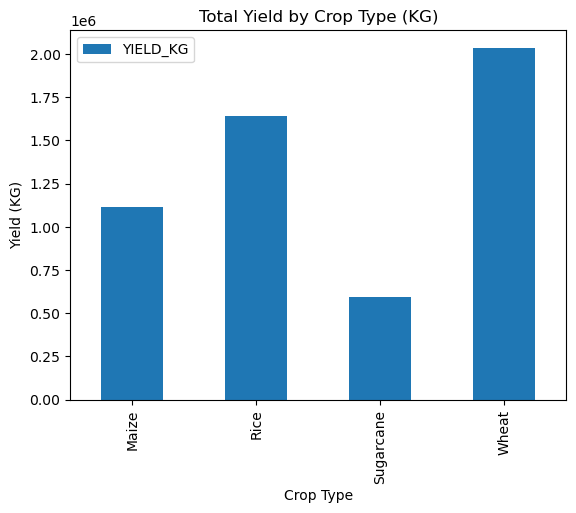

In [20]:
crop_yield.plot(kind='bar')

plt.title('Total Yield by Crop Type (KG)')
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')

plt.show()

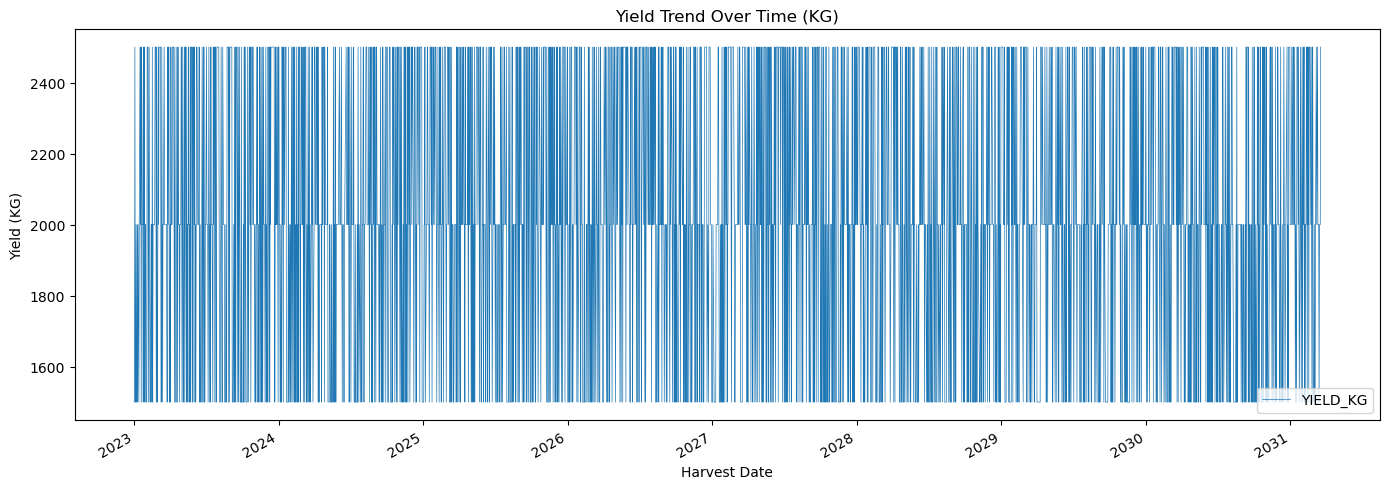

In [21]:
crop_pivot.plot(kind='line', figsize=(14, 5), linewidth=0.5)

plt.title('Yield Trend Over Time (KG)')
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')

plt.tight_layout()
plt.savefig('crop_yield_trend.png', dpi=300)

plt.show()